# Análogos en la Tierra de entornos de Marte

**Prototipo conjunto:** consulta marciana → candidatos terrestres. Reúne fuentes verificadas,
armonización espacial, variables derivadas, normalización y comparación de búsquedas.
El resultado es similitud ambiental **relativa**, a escala regional; todavía no demuestra
equivalencia geológica ni aptitud para aterrizajes.

Ejecutar en orden con `marte/.venv/bin/python`. Dependencias:
`marte/.venv/bin/python -m pip install -r analogos/requirements.txt`.
Los algoritmos largos están separados por responsabilidad en [analogos/](./analogos/README.md).
El notebook conserva las decisiones, fórmulas, ejemplos y resultados visibles.

Se leen únicamente cuatro GeoTIFF pequeños y su catálogo de Hugging Face, a memoria y con
hashes verificados. No se descargan los originales grandes ni se crean nuevos TIFF.
Las figuras, el ranking CSV y el informe JSON se guardan en `analogos/resultados/`.

In [1]:
from pathlib import Path
import sys

RAIZ = Path.cwd()
if RAIZ.name == "analogos":
    RAIZ = RAIZ.parent
if not (RAIZ / "analogos").is_dir():
    raise RuntimeError("Ejecuta desde la raíz del repositorio")
if Path(sys.prefix).resolve() != (RAIZ / "marte/.venv").resolve():
    raise RuntimeError("Selecciona el kernel marte/.venv/bin/python")
sys.path.insert(0, str(RAIZ))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

from analogos.datos import cargar_datos, tabla_fuentes, tabla_variables
from analogos.armonizacion import armonizar
from analogos.variables import agregar_derivadas, construir_tablas, comprobaciones_unidades
from analogos.normalizacion import Normalizacion, PercentilEmpirico, distancia_percentiles
from analogos.metodos import celda_marciana
from analogos.evaluacion import dividir_bloques, comparar_metodos, buscar_analogos
from analogos import graficas
from analogos.salidas import tabla_markdown, tabla_candidatos, guardar_resultados, guardar_figura
from analogos.comprobaciones import verificar

print("Python:", sys.executable, "· scikit-learn:", sklearn.__version__)

Python: /home/renato/Desktop/HSpace/marte/.venv/bin/python · scikit-learn: 1.9.1


/home/renato/Desktop/HSpace/marte/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Decisiones del experimento

La consulta de ejemplo está cerca de −5,4° / 137,8° en Marte. Se usa el **centro regional
QC más próximo**, que se mostrará explícitamente; no se atribuyen sus medias al punto exacto.

Los filtros terrestres son una decisión exploratoria: vegetación ≤20 %, agua ≤5 % y clases
urbanas ≤2 %. Pueden modificarse aquí; no son umbrales científicos validados. Se exige
cobertura suficiente y nunca se interpreta un desconocido como terreno libre.
La vegetación, el agua y las ciudades **no se inventan en Marte** para completar características.

In [3]:
REVISION_HF = "dd6f0fcd1f9d206c1860b4a808336e196203c144"
SEMILLA = 42
K_VECINOS = 10
CELDA_M = 120_000
RADIO_RELIEVE_M = 300_000
PESOS = np.array([1.0, 1.0, 1.0])  # albedo, Q absorbido, relieve
CONSULTA = {"latitud": -5.4, "longitud": 137.8}
FILTROS = dict(max_vegetacion=.20, max_agua=.05, max_ciudades=.02,
               min_cobertura=.90, min_cobertura_vegetacion=.75)
SALIDA = RAIZ / "analogos/resultados"

## 2. Armonización: qué da cada dataset

La tabla muestra **entrada → transformación previa → salida disponible**. Las fechas son
las del producto, no la fecha de descarga. Unidades coincidentes no hacen equivalentes
épocas, atmósferas, referencias verticales ni definiciones de albedo.
Los detalles de procedencia están en [fuentes.md](./analogos/fuentes.md).

In [4]:
fuentes = []
for r in tabla_fuentes():
    url = r["fuente_url"].removeprefix("../")
    fuentes.append({"Dataset": f"[{r['dataset']}]({url})", "Planeta": r["planeta"],
                    "Entrada": r["entrada"], "Transformación": r["transformacion"],
                    "Salida": r["salida"]})
display(Markdown(tabla_markdown(fuentes)))

| Dataset | Planeta | Entrada | Transformación | Salida |
| --- | --- | --- | --- | --- |
| [NASADEM HGT.001](https://www.earthdata.nasa.gov/data/catalog/lpcloud-nasadem-hgt-001) | Tierra | Elevación, m EGM96; 1″ (~30 m); SRTM 2000 | Media remota a 15″, redondeo Int16; media válida y cobertura de 240×240 celdas a 1° | elevacion [m] y cobertura de datos [1] |
| [NASA POWER](https://power.larc.nasa.gov/docs/services/arcgis/) | Tierra | GHI [W/m²] y albedo [1]; nativos 1°; climatología 2001–2025 | Exportación numérica anual month=13; sin cambio de unidades; relleno a NaN | ghi [W/m²], albedo [1] |
| [MCD12Q1.061 + Natural Earth](https://zenodo.org/records/8367523) | Tierra | Clases IGBP 2021; mosaico ~15″; océano cartográfico 1:10M | Vecino nativo a malla 15″; clase 13=urbano,17=agua; océano solo en huecos; conteos/validados a 1° | ciudades, agua y cobertura clasificada [1] |
| [MOD44B.061 / ICDC](https://www.geo.uni-hamburg.de/en/service/icdc/data/land/modis-vcf-forest.html) | Tierra | No vegetado [%]; CMG 0,5°; ciclo 2021-03-05 a 2022-03-04 | vegetacion=(100−no vegetado)/100; fill 127→NaN; media de celdas válidas 2×2 a 1° | vegetacion [1], cobertura de celdas CMG [1] |
| [MGS MOLA](https://pds-geosciences.wustl.edu/missions/mgs/megdr.html) | Marte | Altura [m] sobre el areoide; ~463 m, 128 píxeles/grado | Reproyección al CRS esférico marciano y media válida a 1°; se conserva advertencia de bordes | elevacion [m] |
| [Generador GHI del proyecto](marte/origen_ds_gui_Y_albeolo/generar_ghi.py) | Marte | Modelo esférico: S = 590 W/m², transmisión 0,75, oblicuidad 25,19°, Ls = 18,9° | Media diaria analítica; malla nativa 1° preservada; latitudes interpretadas como planetocéntricas | ghi [W/m²]; modelo de una estación, no media anual |
| [MGS TES / ASU](https://www.mars.asu.edu/data/tes_albedo/) | Marte | VICAR albedo Lambert bolométrico [1], 8 píxeles/grado | Rotación de 1.440 columnas a −180..180; alfa PNG solo como NoData; media válida 8 × 8 a 1° | albedo [1]; rango fuente≈0,081–0,321 |
| [Mars Express OMEGA](https://pds-geosciences.wustl.edu/mex/mex-m-omega-5-ddr-global-maps-v1/) | Marte | PDS IMG entero de 16 bits; índices OSP1/2/3 y BD2000; ~40 píxeles/grado | IMG×SCALING_FACTOR+OFFSET; corrección de posición sin cambiar valores; media de detecciones y cobertura a 1° | osp1/osp2/osp3/piroxeno [1] y coberturas [1] |

### Significado preciso de las variables de entrada y salida

La carga conserva las unidades: convierte a matrices Float64 y mantiene `NaN` como ausencia.
Las coberturas de datos son fracciones entre 0 y 1; **no** son albedo, vegetación ni abundancia
mineral. En MOD44B indican celdas CMG conocidas, no cobertura interna de recuperaciones de 250 m.
Los índices OMEGA son adimensionales y pueden superar 1; no son porcentajes de mineral.

In [5]:
variables = [{"Planeta": r["planeta"], "Variable": r["variable"],
              "Significado": r["significado"],
              "Unidades entrada → salida": f"{r['unidad_entrada']} → {r['unidad_salida']}"}
             for r in tabla_variables()]
display(Markdown(tabla_markdown(variables)))
brutos = cargar_datos(RAIZ, revision=REVISION_HF)
print("Revisión HF fijada:", brutos["procedencia"]["revision"])
print("Bytes descargados:", brutos["procedencia"]["bytes_descargados"])

| Planeta | Variable | Significado | Unidades entrada → salida |
| --- | --- | --- | --- |
| tierra | elevacion | Altura sobre la referencia vertical del planeta; no nivel absoluto común | m → m |
| tierra | ghi | Irradiancia solar descendente media sobre un plano horizontal | W/m² → W/m² |
| tierra | albedo | Fracción radiativa reflejada según la definición del producto | 1 → 1 |
| tierra | ciudades | Proporción de píxeles IGBP urbanos entre los clasificados | 1 → 1 |
| tierra | agua | Proporción de píxeles de agua entre los clasificados, incluido océano suplementario | 1 → 1 |
| tierra | vegetacion | Fracción superficial estimada por MOD44B sobre recuperaciones válidas | 1 → 1 |
| marte | elevacion | Altura sobre la referencia vertical del planeta; no nivel absoluto común | m → m |
| marte | ghi | Irradiancia solar descendente media sobre un plano horizontal | W/m² → W/m² |
| marte | albedo | Fracción radiativa reflejada según la definición del producto | 1 → 1 |
| marte | osp1 | Parámetro espectral OMEGA; no porcentaje de olivino | 1 → 1 |
| marte | osp2 | Segundo parámetro espectral OMEGA; no abundancia porcentual | 1 → 1 |
| marte | osp3 | Tercer parámetro espectral OMEGA; definición distinta de OSP1/OSP2 | 1 → 1 |
| marte | piroxeno | Parámetro de absorción espectral OMEGA; no porcentaje de piroxeno | 1 → 1 |

Revisión HF fijada: dd6f0fcd1f9d206c1860b4a808336e196203c144
Bytes descargados: 1321261


### De grados a un soporte espacial comparable

Un grado mide unos 111 km en Tierra y 59 km en Marte en el ecuador. No basta con que ambos
mapas tengan 360 × 180 celdas. Se agrega **cada planeta por separado** a la proyección
[sinusoidal](https://proj.org/en/stable/operations/projections/sinu.html), con su propio radio:
Tierra autálica 6.371.007,181 m; Marte 3.396.190 m.

Para longitud $\lambda$ y latitud $\varphi$ en radianes:

$$
x=R\lambda\cos\varphi,\quad y=R\varphi,
\qquad \Delta x=\Delta y=120\,000\;\mathrm m.
$$

Cada cuadrado completo tiene **14.400 km² nominales en el modelo esférico**. Se excluyen
cuadrados recortados por el borde del planeta. No se afirma área elipsoidal exacta ni detalle
nativo de 120 km: las entradas ya son medias de 1°.

Para valor $v_i$, cobertura conocida $c_i$ y peso de remuestreo $a_i$, se calcula

$$
\bar v=\frac{\sum_i a_i c_i v_i}{\sum_i a_i c_i},
\qquad c_{\rm salida}=\frac{\sum_i a_i c_i}{\sum_i a_i}.
$$

Se agregan numerador y denominador con [`Rasterio.average`](https://rasterio.readthedocs.io/en/stable/topics/resampling.html).
Si el denominador vale cero, la salida es `NaN`. Se supone cobertura uniforme dentro de cada
píxel de origen; no se reconstruye su distribución interna. Los ceros observados siguen siendo datos.
Los pesos de `average` aproximan los solapes durante la reproyección; no son una integración geodésica exacta de polígonos.

In [6]:
armonizados = armonizar(brutos, celda_m=CELDA_M)
geometrias = [{"Planeta": p, "Entrada": "180 × 360, 1°",
               "Salida filas × columnas": str(a["geometria"]["forma"]),
               "Celda [km]": a["celda_m"] / 1000,
               "Área nominal [km²]": a["geometria"]["area_nominal_km2"]}
              for p, a in armonizados.items() if p in ("tierra", "marte")]
display(Markdown(tabla_markdown(geometrias)))

| Planeta | Entrada | Salida filas × columnas | Celda [km] | Área nominal [km²] |
| --- | --- | --- | --- | --- |
| tierra | 180 × 360, 1° | [167, 334] | 120 | 14400 |
| marte | 180 × 360, 1° | [89, 178] | 120 | 14400 |

## 3. Variables derivadas: fórmulas, ejemplos y unidades

**Proxy solar absorbido**: entrada albedo medio $A\,[1]$, GHI medio $G\,[\mathrm{W\,m^{-2}}]$;
salida $Q\,[\mathrm{W\,m^{-2}}]$:

$$
Q=(1-A)G;\qquad A=0{,}25,\;G=200\;\Rightarrow Q=150\;\mathrm{W\,m^{-2}}.
$$

Es un proxy de **producto de medias agregadas**, no una observación de absorción:
$(1-\bar A)\bar G$ puede diferir de $\overline{(1-A)G}$. Interpretar el albedo Lambert
marciano como reflectancia efectiva añade otra aproximación. No se iguala su estación Ls=18,9°
con la climatología anual terrestre.

**Energía equivalente de 24 h**, solo como diagnóstico:

$$
E_{24}=Q\frac{24\;\mathrm h}{1000}
\quad[\mathrm{kWh\,m^{-2}}];\qquad 150\times24/1000=3{,}6\;\mathrm{kWh\,m^{-2}}.
$$

W × h / 1000 da kWh. Este intervalo común de 24 h **no es un sol marciano** ni una predicción
de energía instantánea. Como es una transformación de Q, no se añade como otra variable al ranking.

**Relieve regional**: entrada medias DEM $h_i\,[\mathrm m]$ en un disco geodésico de radio
300 km; salida dispersión poblacional $H\,[\mathrm m]$:

$$
\bar h=\frac1n\sum_i h_i,\qquad
H=\sqrt{\frac1n\sum_i(h_i-\bar h)^2}.
$$

Ejemplo: alturas 100, 200, 300, 400 y 500 m → $H\approx141{,}42$ m. Sumar 8.000 m a todas
no cambia H. Así no se compara directamente el cero EGM96 terrestre con el areoide marciano;
esto no elimina otras diferencias de geoide o resolución.

[`BallTree`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.BallTree.html)
encuentra vecinos con distancia haversine y el radio del planeta. Se exigen ≥5 celdas completas,
cobertura DEM ≥90 % y ≥80 % de vecinos disponibles. El resultado no es pendiente ni rugosidad
de un lugar de aterrizaje: describe dispersión de **medias regionales**.

In [7]:
armonizados = agregar_derivadas(armonizados, radio_local_m=RADIO_RELIEVE_M)
ejemplos_unidades = comprobaciones_unidades()
display(Markdown(tabla_markdown([ejemplos_unidades])))

| albedo_entrada_1 | ghi_entrada_W_m2 | q_salida_W_m2 | energia_salida_kWh_m2_por_24h | relieve_ejemplo_m | invariante_a_offset_vertical | unidades |
| --- | --- | --- | --- | --- | --- | --- |
| 0.25 | 200 | 150 | 3.6 | 141.42 | True | (1)×W/m²=W/m²; W/m²×h/1000=kWh/m²; σ(elevación[m])=m |

### Variables que entran en la distancia

$X=(A,Q,H)$: **albedo, proxy solar absorbido y relieve regional**. No se añaden simultáneamente
GHI, Q y energía de 24 h, porque se repetiría información. A y Q aún pueden estar correlacionados;
los pesos iniciales iguales son explícitos, no estimados como importancias científicas.

Elevación absoluta y GHI se guardan como contexto. Vegetación, agua y ciudades filtran Tierra;
los minerales marcianos quedan como contexto sin un equivalente terrestre disponible.
Las referencias para normalizar se fijan **antes** de los filtros opcionales: Tierra sobre su
huella DEM con calidad suficiente; Marte sobre sus celdas QC. No son toda la superficie de cada planeta.

In [8]:
tablas = construir_tablas(armonizados, **FILTROS)
display(Markdown(tabla_markdown(tablas["tierra"]["resumen_filtros"])))
display(Markdown(tabla_markdown([
    {"Planeta": p, "Referencias QC": t["n_referencia"], "Candidatos elegibles": t["n_elegibles"]}
    for p, t in tablas.items()
])))

| filtro | restantes |
| --- | --- |
| Referencia física antes de filtros de candidatos | 7046 |
| Vegetación conocida y baja | 1119 |
| Agua conocida y baja | 1040 |
| Ciudades conocidas y bajas | 1032 |
| Cobertura de clasificación suficiente | 1032 |
| Cobertura de vegetación suficiente | 1032 |

| Planeta | Referencias QC | Candidatos elegibles |
| --- | --- | --- |
| tierra | 7046 | 1032 |
| marte | 9595 | 9595 |

## 4. Normalización: entrada y salida visibles

Se separan bloques de **10°** por planeta: 60 % de bloques para calibración, 20 % para desarrollo
y 20 % para prueba, con semilla fija. Se ajustan las transformaciones solo con calibración.
Los bloques no se mezclan; no se aplica buffer entre ellos, por lo que puede persistir correlación
espacial cerca de los límites. No es una prueba de generalización geológica.

**Z-score** por planeta $p$ y variable $j$:
$$
z_{p,j}(x)=\frac{x_j-\mu_{p,j}}{\sigma_{p,j}}.
$$
[`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
resta la media y divide por la desviación de calibración; devuelve valores adimensionales no
limitados a 0–1. No elimina outliers ni corrige diferencias físicas entre datasets.

**Percentiles empíricos**, con empates:
$$
P_{p,j}(x)=\frac{\#\{r_j<x_j\}+\tfrac12\#\{r_j=x_j\}}{n_p}.
$$
Devuelven posición relativa 0–1 dentro de la referencia. Se implementan con
[`numpy.searchsorted`](https://numpy.org/doc/stable/reference/generated/numpy.searchsorted.html),
sin ruido aleatorio. Ejemplo: referencia [10,10,20,40] → P(10)=0,25 y P(20)=0,625.
Fuera del rango observado saturan en 0 o 1: no distinguen cuánto se ha extrapolado.

En esta malla cada celda QC completa representa la misma área nominal, por lo que las
referencias tienen igual peso. En una malla angular habría que considerar, por ejemplo, cos(latitud).

In [9]:
particiones = dividir_bloques(tablas, semilla=SEMILLA)
normalizadores = {modo: Normalizacion(modo).fit(tablas, particiones)
                  for modo in ("zscore", "percentiles")}
display(Markdown(tabla_markdown([
    {"Planeta": p, **{nombre: int(mask.sum()) for nombre, mask in sets.items()}}
    for p, sets in particiones.items()
])))

| Planeta | calibracion | desarrollo | prueba |
| --- | --- | --- | --- |
| tierra | 4027 | 1479 | 1540 |
| marte | 5769 | 2058 | 1768 |

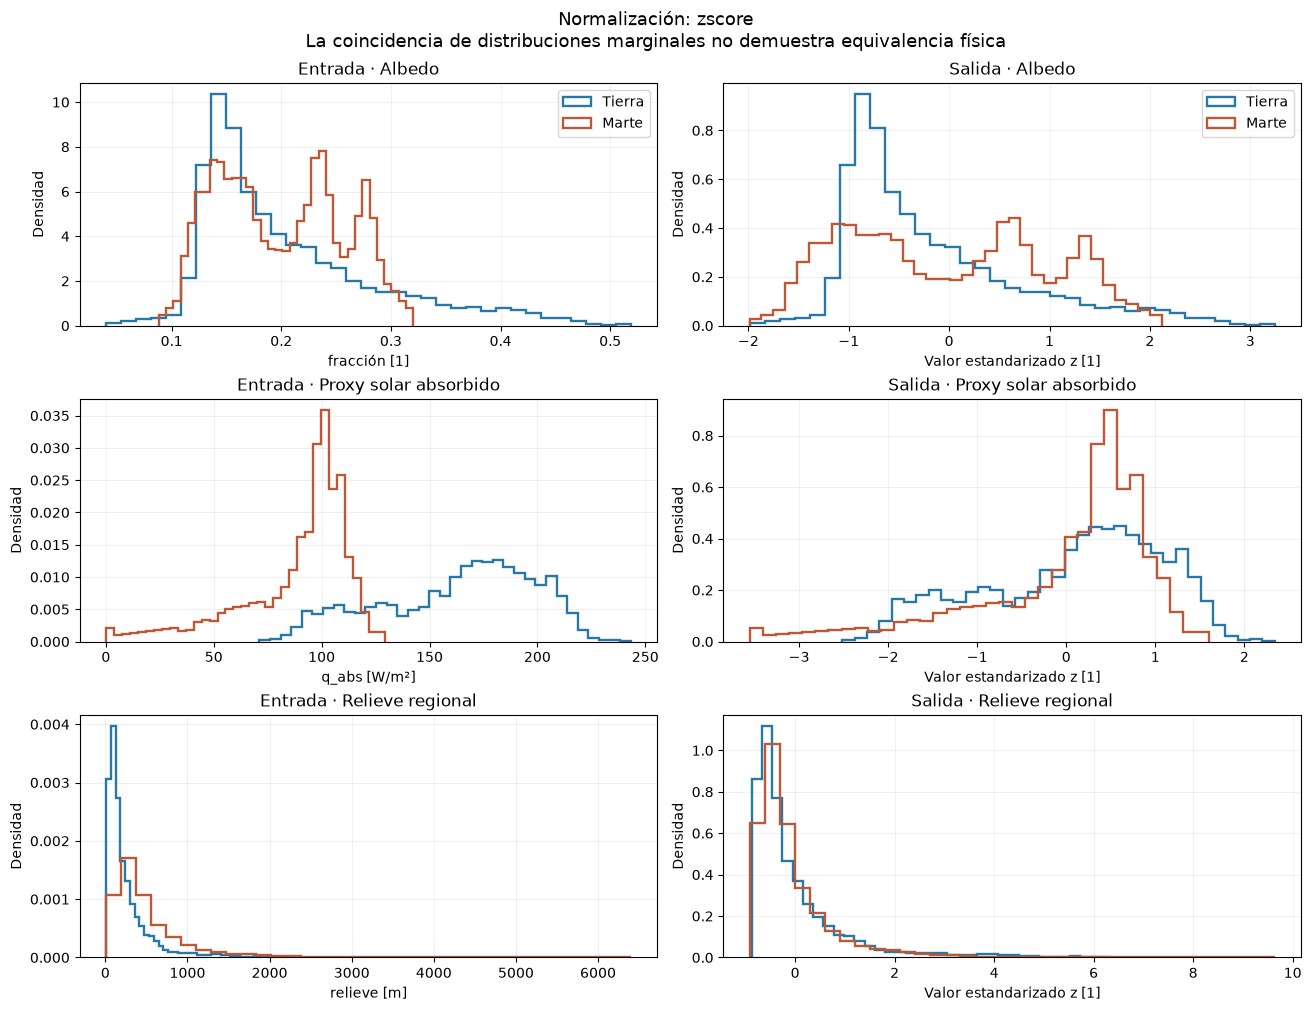

In [10]:
fig = graficas.normalizacion(tablas, normalizadores["zscore"])
guardar_figura(fig, SALIDA / "01_normalizacion_zscore.png")
plt.show()

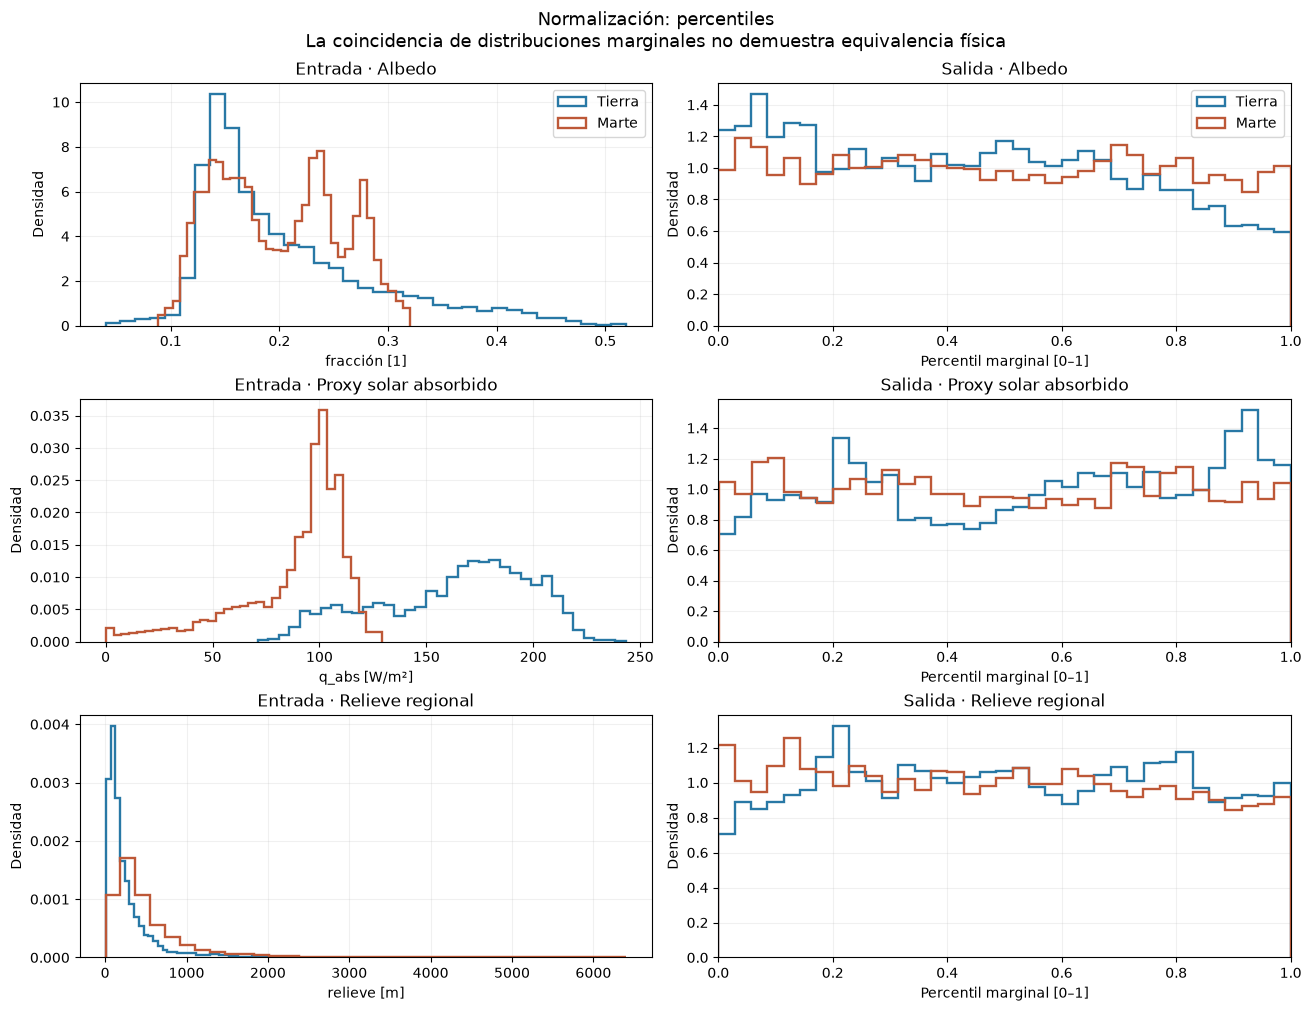

In [11]:
fig = graficas.normalizacion(tablas, normalizadores["percentiles"])
guardar_figura(fig, SALIDA / "02_normalizacion_percentiles.png")
plt.show()

La izquierda conserva las unidades físicas; la derecha muestra la salida del transformador.
Dos distribuciones marginales parecidas tras normalizar **no demuestran** que las celdas
sean equivalentes. Las dependencias entre variables y las diferencias de definición siguen presentes.

## 5. KNN: librería y ejemplo visual

[`sklearn.neighbors.NearestNeighbors`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html)
indexa vectores y devuelve los **k más próximos** y sus distancias. Aquí se usa búsqueda no
supervisada, no un clasificador: no hay etiquetas de “análogo verdadero”.
`kd_tree` busca vecinos exactos para la distancia euclídea; el ajuste recuerda candidatos,
no aprende una relación causal entre planetas.

Entrada: candidatos $N\times p$ y consultas $N_q\times p$, ya normalizados.
Salida: índices y distancias $N_q\times k$. El ejemplo 2D permite ver el círculo de vecinos;
la búsqueda real utiliza las tres características.

Con z-score, la distancia que usa el prototipo es
$$
d_z(m,t)=\sqrt{\frac{\sum_j w_j[z_{M,j}(m_j)-z_{T,j}(t_j)]^2}{\sum_j w_j}}.
$$
Es adimensional. Multiplicar cada eje normalizado por $\sqrt{w_j/\sum_j w_j}$
convierte esta fórmula en la distancia euclídea que calcula la librería.


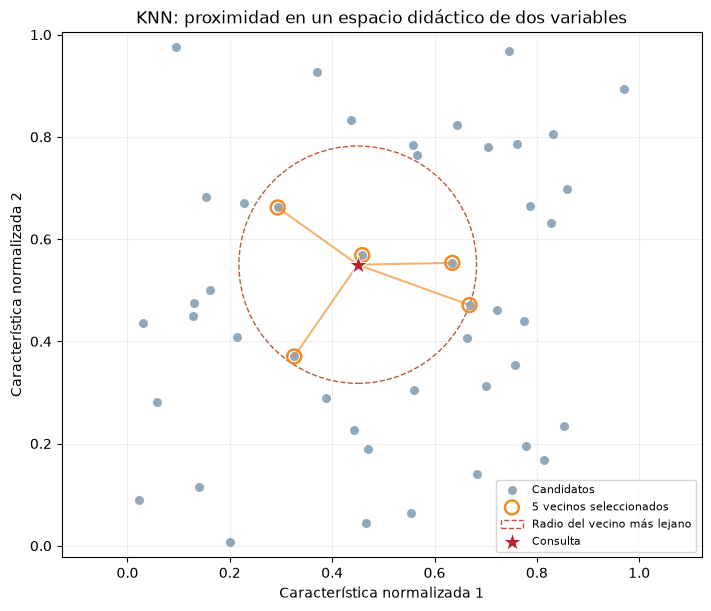

In [12]:
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(SEMILLA)
puntos = rng.uniform(0, 1, (45, 2))
consulta_2d = np.array([.45, .55])
modelo_2d = NearestNeighbors(n_neighbors=5, algorithm="kd_tree").fit(puntos)
distancias_2d, vecinos_2d = modelo_2d.kneighbors(consulta_2d[None])
fig = graficas.ejemplo_knn(puntos, consulta_2d, vecinos_2d[0])
guardar_figura(fig, SALIDA / "03_ejemplo_knn.png")
plt.show()

## 6. Clusters: librería y ejemplo visual

[`sklearn.cluster.KMeans`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
agrupa vectores minimizando la suma de distancias cuadradas a sus centroides:
$$
\min_{C_1,\ldots,C_K}\sum_{c=1}^{K}\sum_{i\in C_c}\|z_i-\mu_c\|^2.
$$
Entrada: vectores normalizados y número K de grupos. Salida: una etiqueta por vector y K
centroides. Los identificadores de grupo son arbitrarios; no son rangos de calidad geológica.

En los datos reales se prueban K=3,5,8 sobre calibración. Se elige la mayor
[`silhouette`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html),
$s=(b-a)/\max(a,b)$, usando una muestra fija de hasta 500 puntos. Mide separación de grupos,
**no** calidad de análogos. a es la distancia media al propio grupo; b, la menor
distancia media a otro grupo. Un cluster cercano puede excluir vecinos buenos al otro lado del límite;
por eso su uso como prefiltro se evalúa aparte.

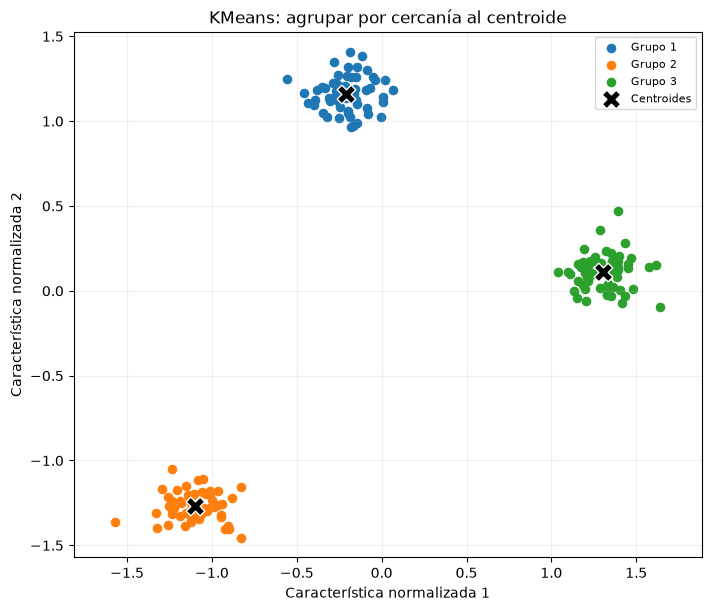

In [13]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

puntos_didacticos, _ = make_blobs(n_samples=180, centers=3, cluster_std=.65, random_state=SEMILLA)
puntos_cluster = StandardScaler().fit_transform(puntos_didacticos)
agrupador_2d = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA)
with threadpool_limits(limits=1):
    etiquetas_2d = agrupador_2d.fit_predict(puntos_cluster)
fig = graficas.ejemplo_clusters(puntos_cluster, etiquetas_2d, agrupador_2d.cluster_centers_)
guardar_figura(fig, SALIDA / "04_ejemplo_clusters.png")
plt.show()

## 7. Distancia de percentiles

Para consulta marciana $m$, candidato terrestre $t$ y pesos positivos $w_j$:
$$
d_P(m,t)=\sqrt{\frac{\sum_j w_j\,[P_{M,j}(m_j)-P_{T,j}(t_j)]^2}{\sum_j w_j}}.
$$
Cada percentil se calcula con **la referencia de su planeta**. La salida es adimensional,
entre 0 y 1. Cero significa los mismos descriptores relativos; no exige los mismos valores
físicos. La distancia no es una probabilidad de ser análogo.

Ejemplo: (0,2;0,7;0,3) frente a (0,3;0,6;0,4), con pesos iguales, da d=0,1.
Transformar cada columna como $z_j=P_j\sqrt{w_j/\sum w}$ permite usar KNN euclídeo exactamente.
**KNN con percentiles y ordenación directa por dP son el mismo criterio matemático**:
su acuerdo comprueba el código, no aporta dos validaciones científicas independientes.

In [14]:
p_marte = np.array([.2, .7, .3])
p_tierra = np.array([[.3, .6, .4]])
d_ejemplo = distancia_percentiles(p_marte, p_tierra, PESOS)[0]
print("Distancia del ejemplo:", d_ejemplo)
assert np.isclose(d_ejemplo, .1)
referencia_empates = PercentilEmpirico().fit(np.array([[10.], [10.], [20.], [40.]]))
print("Percentiles de 10 y 20:", referencia_empates.transform([[10.], [20.]]).ravel())

Distancia del ejemplo: 0.09999999999999999
Percentiles de 10 y 20: [0.25  0.625]


## 8. Comparar y elegir con resultados medibles

Se comparan dos representaciones (z-score y percentiles) y tres buscadores: KNN exacto,
KMeans + KNN en un grupo o en dos grupos próximos. Los grupos se amplían si hace falta
para reunir k candidatos. Normalizadores y centroides solo usan calibración. Los candidatos
indexados incluyen desarrollo y prueba porque el experimento recupera **elementos de una base conocida**.

**Control de robustez:** se retienen anclas terrestres en bloques de desarrollo; se perturban
sus tres valores con ruido gaussiano de 1 % y 5 % del IQR de calibración, dos repeticiones
por nivel. Se recortan albedo a 0–1 y Q/relieve a valores no negativos. No son incertidumbres
instrumentales medidas. Se mide recuperación del original o de un vector físico exactamente empatado:
$$
\mathrm{Hit@k}=\frac1{N_q}\sum_q\mathbf1[\text{ancla equivalente entre los k recuperados}].
$$

**Fidelidad del prefiltro:** consultas marcianas de bloques de desarrollo se comparan con el
resultado exacto de la misma distancia. Para admitir empates en el puesto k:
$$
\mathrm{Recall@k}=\frac1{N_q k}\sum_q\left(
|S_q\cap E_q^{<}|+
\min\{k-|E_q^{<}|,\;|S_q\cap E_q^{=}|\}\right).
$$
Aquí $S_q$ son los k resultados; $E_q^{<}$, los candidatos estrictamente más próximos
que el vecino k exacto; y $E_q^{=}$, los empatados con él, con tolerancia $10^{-12}$.
Se exige recuperar los interiores y solo se permite intercambiar los de frontera.
Sin empates es la fracción de vecinos exactos recuperados. Los tiempos son medianas
de cinco tandas, por consulta; incluyen transformación y búsqueda, no descarga ni ajuste.

**Regla previa:** gana la representación con mayor Hit@k de desarrollo. Un empate de hasta
2 puntos porcentuales favorece percentiles por interpretación relativa. El prefiltro solo
se admite si recall ≥0,99, no pierde más de 1 punto de Hit@k y reduce la latencia al menos 20 %.
Después se evalúa **solo la opción seleccionada** en bloques de prueba. Si falla la fidelidad
de prueba, la consulta real vuelve a KNN exacto, sin retocar hiperparámetros con esa prueba.

Son tasas descriptivas de recuperación y aproximación, **no una validación Tierra–Marte**.
Las perturbaciones de una misma ancla no son muestras independientes para inferencia estadística.

In [15]:
with threadpool_limits(limits=1):
    comparacion = comparar_metodos(tablas, k=K_VECINOS, pesos=PESOS, semilla=SEMILLA)
columnas = ["metodo", "hit_dev", "recall_dev", "ms_consulta", "hit_test", "recall_test"]
display(Markdown(tabla_markdown(comparacion["filas"], columnas)))
seleccion = comparacion["seleccion"]
normalizador = comparacion["normalizadores"][seleccion["modo"]]
print("Seleccionado:", seleccion["metodo"])
print("Regla:", comparacion["criterio"])

| metodo | hit_dev | recall_dev | ms_consulta | hit_test | recall_test |
| --- | --- | --- | --- | --- | --- |
| zscore + knn | 0.96333 | 1 | 0.0067444 | 0.99375 | 1 |
| zscore + clusters (1 grupo) | 0.94667 | 0.93333 | 0.31985 | — | — |
| zscore + clusters (2 grupos) | 0.96333 | 1 | 0.59571 | — | — |
| percentiles + knn | 0.93 | 1 | 0.0057311 | — | — |
| percentiles + clusters (1 grupo) | 0.90667 | 0.83229 | 0.29677 | — | — |
| percentiles + clusters (2 grupos) | 0.93 | 0.925 | 0.57761 | — | — |

Seleccionado: zscore + knn
Regla: Mayor Hit@k de desarrollo; empate de hasta 2 puntos porcentuales favorece percentiles por interpretación relativa. Prefiltro solo si recall >= 0.99 y mejora >= 20% en latencia, sin perder más de 1 punto porcentual de Hit@k.


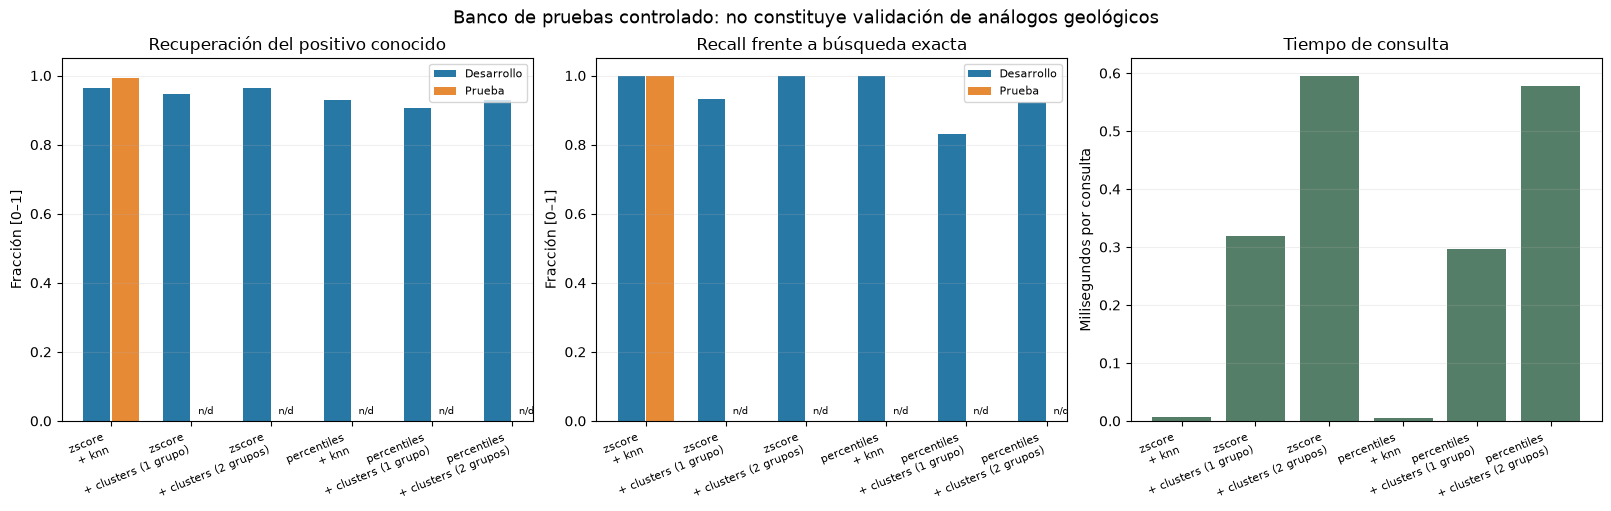

In [16]:
fig = graficas.comparacion(comparacion["filas"])
guardar_figura(fig, SALIDA / "05_comparacion_metodos.png")
plt.show()

Los campos de prueba de métodos no seleccionados aparecen como **n/d**: no se han usado para
volver a elegir. Un Hit alto significa recuperar controles conocidos bajo ese ruido; un
recall de 1 significa reproducir la búsqueda exacta, no hallar un análogo físico verdadero.
La opción que se imprime arriba es la que se utiliza a continuación; no se fuerza que gane
percentiles ni clusters. Las latencias pueden variar según equipo y carga.

| k | silhouette |
| --- | --- |
| 3 | 0.49824 |
| 5 | 0.35187 |
| 8 | 0.32557 |

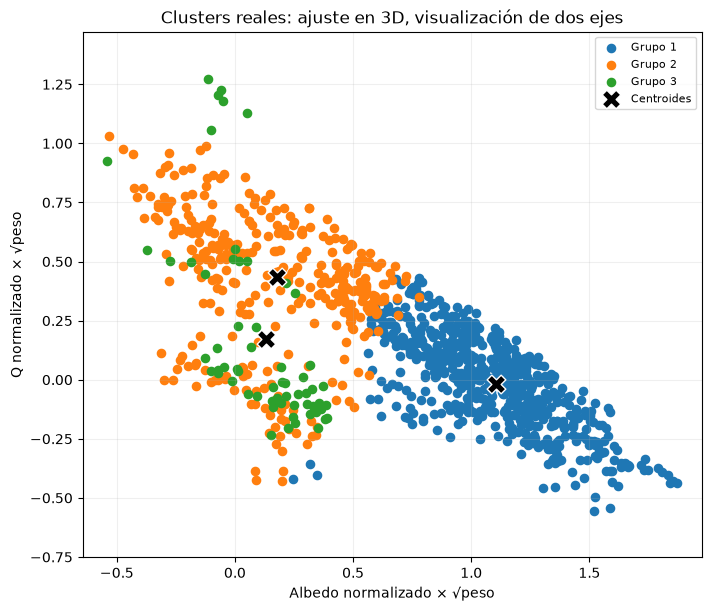

In [17]:
indice_seleccionado = comparacion["indices"][seleccion["modo"]]
display(Markdown(tabla_markdown(indice_seleccionado.evaluacion_clusters)))
fig = graficas.ejemplo_clusters(indice_seleccionado.Z[:, :2],
                               indice_seleccionado.etiquetas,
                               indice_seleccionado.kmeans.cluster_centers_[:, :2])
fig.axes[0].set(title="Clusters reales: ajuste en 3D, visualización de dos ejes",
                xlabel="Albedo normalizado × √peso", ylabel="Q normalizado × √peso")
guardar_figura(fig, SALIDA / "06_clusters_reales.png")
plt.show()

## 9. Consulta marciana y candidatos terrestres

Se muestran las coordenadas realmente usadas y la distancia desde la entrada al centro regional.
La función rechaza una consulta sin referencia QC a menos de 3°. Los vecinos ambientales se
buscan después **entre candidatos terrestres**, no por cercanía de sus coordenadas a las de Marte.

In [18]:
consulta = celda_marciana(tablas["marte"], **CONSULTA)
separacion_km = np.deg2rad(consulta["desplazamiento_angular_grados"]) * armonizados["marte"]["radio_m"] / 1000
print("Coordenadas solicitadas:", CONSULTA)
print("Centro regional utilizado:", consulta["latitud"], consulta["longitud"])
print(f"Separación del centro: {separacion_km:.1f} km")
print("X marciano [albedo, Q W/m², relieve m]:", consulta["X"])
print("Fuera del rango de calibración por variable:",
      normalizador.fuera_referencia("marte", consulta["X"])[0])

Coordenadas solicitadas: {'latitud': -5.4, 'longitud': 137.8}
Centro regional utilizado: -6.162447691256748 137.62522183811947
Separación del centro: 46.4 km
X marciano [albedo, Q W/m², relieve m]: [1.63922037e-01 1.13230909e+02 1.31226983e+03]
Fuera del rango de calibración por variable: [False False False]


In [19]:
indices, distancias, motor_final = buscar_analogos(comparacion, tablas, consulta)
ranking = tabla_candidatos(tablas["tierra"], consulta, indices, distancias, normalizador, PESOS)
display(Markdown(tabla_markdown(ranking, ["rango", "latitud", "longitud", "distancia",
                                           "albedo", "q_abs_W_m2", "relieve_m", "vegetacion"])))
print("Motor final:", motor_final, "· Representación:", normalizador.modo)

| rango | latitud | longitud | distancia | albedo | q_abs_W_m2 | relieve_m | vegetacion |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 29.026 | 56.412 | 0.13749 | 0.16992 | 201.93 | 585.66 | 0.12728 |
| 2 | 27.947 | 57.06 | 0.15491 | 0.16816 | 202.61 | 637.95 | 0.095163 |
| 3 | 29.026 | 57.646 | 0.17998 | 0.16088 | 202.43 | 544.54 | 0.14466 |
| 4 | 33.343 | 62.921 | 0.18964 | 0.19225 | 194.32 | 613.36 | 0.18487 |
| 5 | 27.947 | 58.282 | 0.2047 | 0.18547 | 199.79 | 549.36 | 0.070128 |
| 6 | 31.184 | 67.75 | 0.2381 | 0.19043 | 203.21 | 637.65 | 0.11535 |
| 7 | 30.105 | 69.493 | 0.25991 | 0.17847 | 191.17 | 718.34 | 0.19887 |
| 8 | 27.947 | 66.833 | 0.2702 | 0.19324 | 198.57 | 519.68 | 0.14217 |
| 9 | 32.264 | 68.543 | 0.29768 | 0.19209 | 190.95 | 713.85 | 0.13541 |
| 10 | 33.343 | 52.587 | 0.30157 | 0.17535 | 192.97 | 463.55 | 0.10362 |

Motor final: knn · Representación: zscore


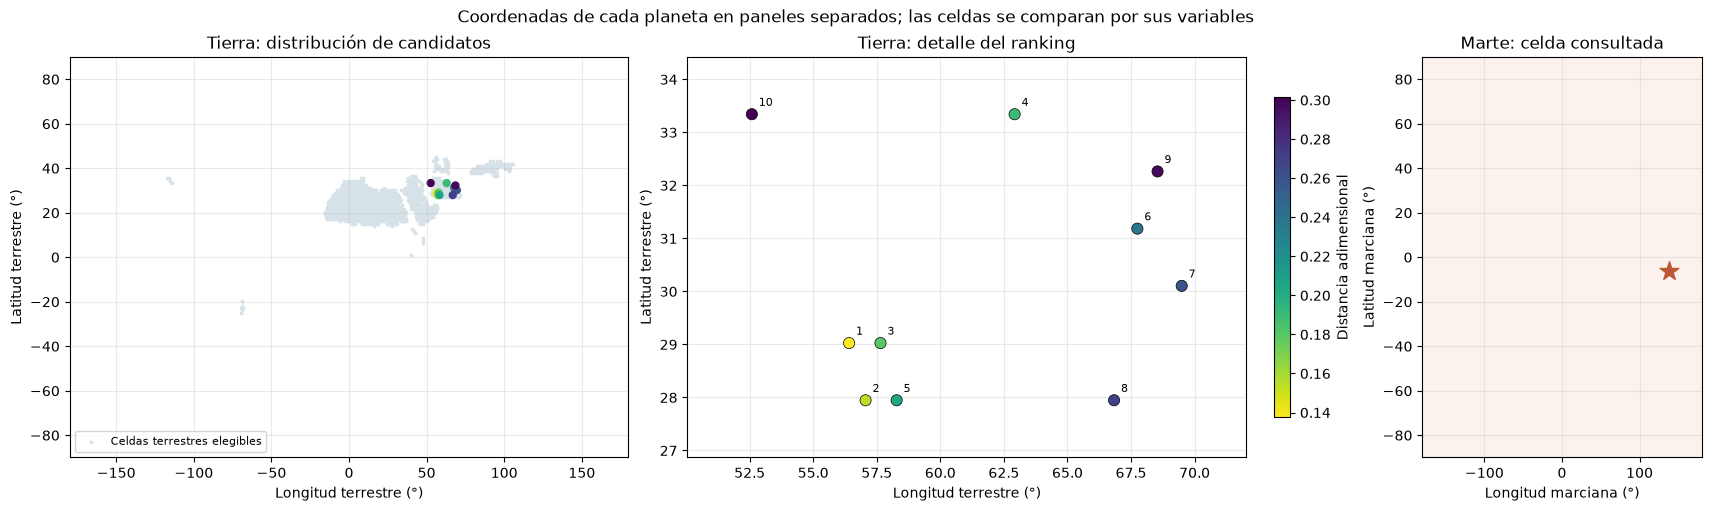

In [20]:
fig = graficas.mapa_candidatos(tablas["tierra"], consulta, indices, distancias)
guardar_figura(fig, SALIDA / "07_candidatos_tierra_y_consulta_marte.png")
plt.show()

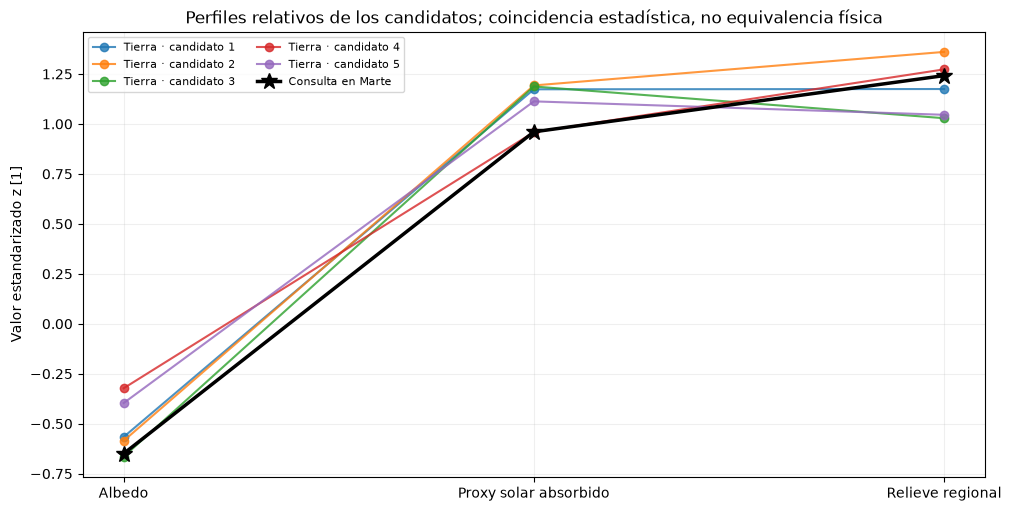

In [21]:
fig = graficas.perfiles(tablas["tierra"], consulta, indices, normalizador)
guardar_figura(fig, SALIDA / "08_perfiles_relativos.png")
plt.show()

Las distancias son adimensionales y dependen de las referencias, variables, pesos y filtros.
Con z-score no están limitadas a 0–1. La tabla conserva los valores físicos para comprobar
qué diferencias se están aceptando; no se muestran “porcentajes de semejanza”.

No hay temperatura equivalente, composición mineral terrestre ni verificación sobre terreno.
La vegetación es una estimación media sobre recuperaciones válidas; las clases urbanas/agua
son proporciones categóricas. Una celda elegible regional no garantiza ausencia local de esos elementos.
MOLA conserva la advertencia de geometría de la [auditoría de origen](./marte/auditoria_tiffs/INFORME.md).

## 10. Comprobaciones y salida reproducible

Se comprueban unidades y ejemplos, invariancia del relieve a un offset de altura, empates de
percentiles, equivalencia de la fórmula ponderada con KNN, preservación de ceros y NoData,
recall que no oculta vecinos interiores, separación de particiones y referencias independientes del filtro de vegetación.
El CSV guarda coordenadas, valores físicos y contribuciones cuadradas a la distancia.
El JSON conserva hashes, revisión HF, parámetros, población de referencia, método aplicado, posible fallback, versiones, comprobaciones y métricas.
No se publica automáticamente nada ni se guardan nuevos TIFF.

In [22]:
checks = verificar(armonizados, tablas, comparacion, brutos)
display(Markdown(tabla_markdown([{k: v for k, v in checks.items() if k != "unidades_y_ejemplos"}])))
configuracion = dict(revision_hf=REVISION_HF, semilla=SEMILLA, k=K_VECINOS, celda_m=CELDA_M,
                     radio_relieve_m=RADIO_RELIEVE_M, pesos=PESOS, filtros=FILTROS)
archivos = guardar_resultados(SALIDA, ranking, comparacion, tablas, consulta,
                              armonizados["procedencia"], configuracion, motor_final, checks)
archivos

| percentiles_con_empates | distancia_percentiles_independiente | knn_igual_a_formula_ponderada | recall_no_oculta_vecinos_interiores | particiones_disjuntas | referencias_independientes_de_filtros | ceros_validos_y_nodata_conservados |
| --- | --- | --- | --- | --- | --- | --- |
| True | True | True | True | True | True | True |

{'ranking': '/home/renato/Desktop/HSpace/analogos/resultados/candidatos.csv',
 'informe': '/home/renato/Desktop/HSpace/analogos/resultados/informe.json'}

## Anexo — distancia de Mahalanobis para ampliar el proyecto

La distancia euclídea trata los ejes como independientes. Mahalanobis tiene en cuenta su
covarianza: puede evitar contar dos veces direcciones correlacionadas, como albedo y proxy solar.
Para dos vectores **ya armonizados y normalizados**:

$$
d_M(x,y)=\sqrt{(z_x-z_y)^T\Sigma_\lambda^{-1}(z_x-z_y)},
\qquad
\widehat\Sigma=\frac1n\sum_i(z_i-\bar z)(z_i-\bar z)^T.
$$

Con regularización:
$$
\Sigma_\lambda=(1-\lambda)\widehat\Sigma+
\lambda\frac{\operatorname{tr}(\widehat\Sigma)}p I,\qquad 0\le\lambda\le1.
$$

[`sklearn.covariance.LedoitWolf`](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.LedoitWolf.html)
estima esa contracción con calibración. La inversa regularizada reduce inestabilidad ante
variables redundantes; no homogeneiza épocas, atmósferas ni definiciones de albedo.
La covarianza debe corresponder a una población declarada: aquí se ilustra con referencias
terrestres de calibración, antes de los filtros opcionales.

El siguiente cálculo es **solo una demostración de futuro** y no vuelve a elegir el método
con los resultados de prueba. La distancia entre un par usa su diferencia; el método
`modelo.mahalanobis(X)` de scikit-learn calcula, en cambio, distancias **cuadradas al centro**.

In [23]:
from sklearn.covariance import LedoitWolf

X_calibracion = tablas["tierra"]["X"][particiones["tierra"]["calibracion"]]
Z_calibracion = normalizador.transform("tierra", X_calibracion)
covarianza = LedoitWolf().fit(Z_calibracion)
z_marte = normalizador.transform("marte", consulta["X"])[0]
z_tierra = normalizador.transform("tierra", tablas["tierra"]["X"][indices[0]])[0]
delta = z_marte - z_tierra
d_mahalanobis = np.sqrt(delta @ covarianza.precision_ @ delta)
print("Mahalanobis del primer par, solo demostración:", d_mahalanobis)
print("Contracción λ:", covarianza.shrinkage_)

Mahalanobis del primer par, solo demostración: 0.2760714927828317
Contracción λ: 0.012517746650183993


Para adoptarla: añadir variables físicamente comparables, declarar población y calidad,
regularizar la covarianza solo con calibración y repetir el protocolo con bloques espaciales.
Una covarianza global puede no describir distintos regímenes; no se supone gaussianidad ni
que una sola elipse represente todos los ambientes. Para escalar, comparar coste e independencia
de variables y validar candidatos con información externa antes de llamarlos análogos reales.